<a href="https://colab.research.google.com/github/HatamiM12/Machine-Learning-Training/blob/main/LinearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<function matplotlib.pyplot.show(close=None, block=None)>

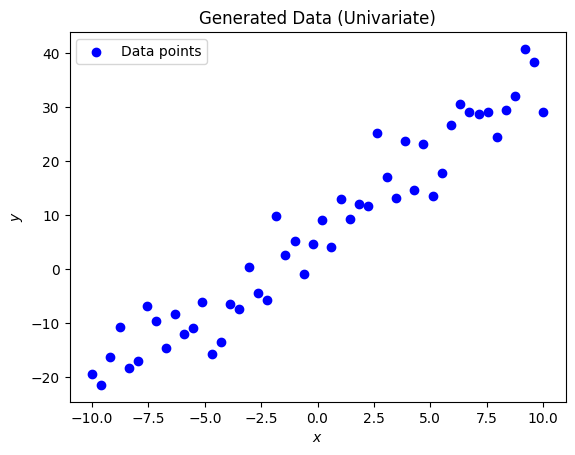

In [ ]:
#Generate Synthetic Data
import numpy as np
import matplotlib.pyplot as plt
def generate_data(n_samples=50, noise=5.0):
  np.random.seed(42)
  X = np.linspace(-10, 10, n_samples)
  # Ground truth line: y = 3x + 8
  true_slope = 3
  true_intercept = 8
  noise = np.random.randn(n_samples) * noise
  y = true_slope * X + true_intercept + noise
  return X, y

#plot
X, y = generate_data(n_samples=50, noise=5.0)
plt.scatter(X, y, color='blue', label='Data points')
plt.title("Generated Data (Univariate)")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show

In [ ]:
# Hypothesis: h_w(x) = w_0 + w_1 * x_1
def h_w(X, w):
  return w[0] + w[1] * X
# Linear Regression using closed-form solution
def linear_regression_closed_form(X, y):
      # Adding bias term (x_0 = 1) to input vector X
      X_b = np.c_[np.ones((len(X), 1)), X]
      # Closed-form solution: w = (X^T * X)^-1 * X^T * y
      w = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
      return w

# Get parameter vector w
w = linear_regression_closed_form(X, y)
print(f"Parameters (w): ")
print(f"w_1 = {w[1]:.2f}, w_0 = {w[0]:.2f}")

Parameters (w): 
w_1 = 2.86, w_0 = 6.87


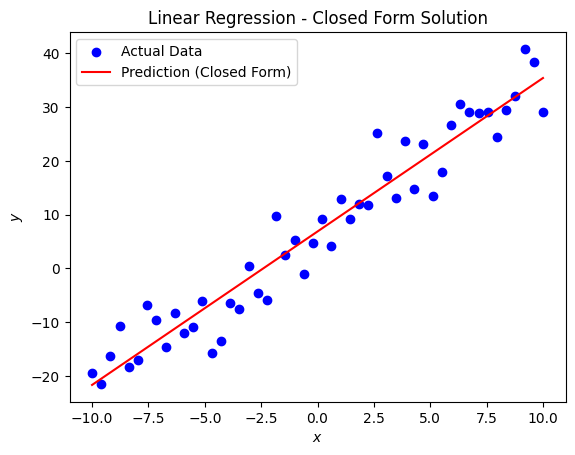

In [ ]:
y_pred = h_w(X, w)

plt.scatter(X, y, color = 'Blue', label = 'Actual Data')
plt.plot(X, y_pred, color='red', label='Prediction (Closed Form)')
plt.title("Linear Regression - Closed Form Solution")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()

In [ ]:
# Function to generate polynomial features (input matrix X')


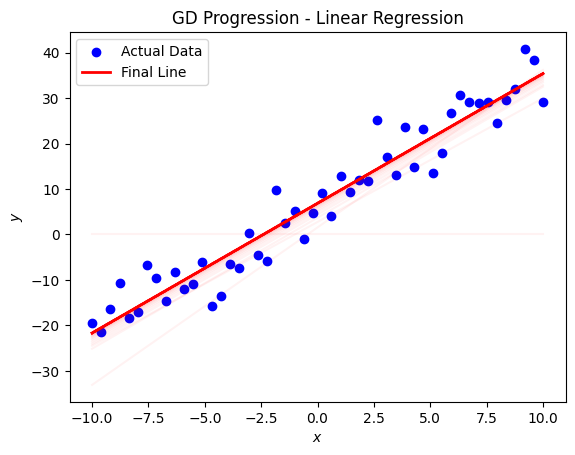

In [ ]:
#Implementing Gradient Decsent for linear regression
# SSE cost function
def cost_function(X, y, w):
  return np.sum((h_w(X, w) - y) ** 2) / len(X)

# Gradient descent
def gradient_descent(X, y, w, alpha, num_iters):
  m = len(X)
  cost_history = []
  w_history = [w.copy()]

  for i in range(num_iters):
    #updates
    gradient_w0 = np.sum(h_w(X,w ) - y) / m
    gradient_w1 = np.sum((h_w(X, w) - y) * X) / m
    w[0] -= alpha * gradient_w0
    w[1] -= alpha * gradient_w1
    cost_history.append(cost_function(X, y, w))
    # Store a copy of w
    w_history.append(w.copy())

  return w, cost_history, w_history

X, y = generate_data(n_samples= 50, noise = 5)
w_initial = [0,0] #start with w0 = 0 & w1 = 0
lr = 0.05 #learning rate
num_iters = 500
#Run function
w_final , cost_history, w_history = gradient_descent(X, y, w_initial, lr, num_iters)
#ploat Generated Data
plt.scatter(X, y, color = 'blue', label = 'Actual Data')




for idx, w in enumerate(w_history[::num_iters // 100]):
  line_alpha = 0.15 + 0.85 * (idx) / 100
  plt.plot(X, h_w(X, w), color='red', alpha=lr)


plt.plot(X, h_w(X, w_final), color='red', lw=2, label='Final Line')

plt.title("GD Progression - Linear Regression")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.show()

In [ ]:
#Define a convex function
def J_convex(w):
  return w[0] ** 2 + 2 * w[1] ** 2

def grad_J_convex(w):
  return np.array([2 * w[0] , 4 * w[1]])

In [ ]:
#Implement Gradient descent
def gradient_descent(grad, w_init, learning_rate = 0.1, n_steps = 20):
  w = np.array(w_init, dtype = float)
  path = [w.copy()]
  for step in range(n_steps):
    grad_w = grad(w)

    w -= learning_rate * grad_w
    path.append(w.copy())

  return np.array(path)

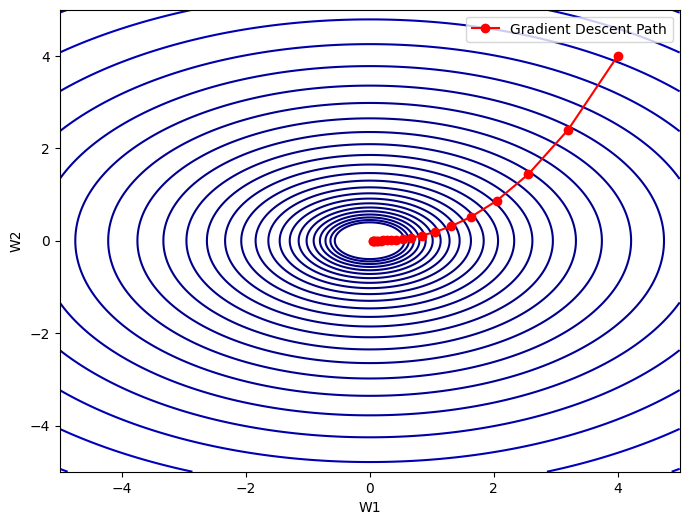

In [ ]:
#Visulize the GD path
w_init = [4,4]
path_convex = gradient_descent(grad_J_convex, w_init, learning_rate= 0.1, n_steps=20)

w1_vals = np.linspace(-5, 5, 400)
w2_vals = np.linspace(-5, 5, 400)
w1, w2 = np.meshgrid(w1_vals, w2_vals)
J_vals = J_convex([w1, w2])

plt.figure(figsize = (8,6))
contour_levels = np.logspace(-0.5, 3, 35)
plt.contour(w1, w2, J_vals, levels = contour_levels, cmap = 'jet')
path_x, path_y = path_convex[:, 0], path_convex[:, 1]
plt.plot(path_x, path_y, marker = 'o', color = 'red', label = 'Gradient Descent Path')
plt.xlabel("W1")
plt.ylabel("W2")
plt.legend()
plt.show()